# Figure 2B split: pseudotime landscape and per-branch cells

The authors asked for the old Figure 2B composite (pseudotime landscape + segmented trajectory arrows + five
branch maps) to be split: **(1)** the pseudotime UMAP on its own, **(2)** the neutrophil and monocyte
branch cells as separate maps for the main figure, with **Meg, Mast and Baso moved to the supplement**.

Display only. Every panel reads `reference_workspace/Figure/fig2/data/fig2c_pseudotime_masks.csv` — the same
stored coordinates, Palantir pseudotime and branch masks behind the current composite
(`analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_2c_trajectory_overview.png`).
No branch refitting, no new mask estimation, no metaclone calculation. Colours, marker areas and the root
star follow that composite; the shared axis limits are the only addition, so the maps are comparable.

Environment **chronoclone**, `/path/to/ChronoClone/.runtime/chronoclone`
(→ `/path/to/ChronoClone/.runtime/chronoclone`), kernel **chronoclone-paper**;
versions and the execution command are printed below.


In [1]:

import sys, platform, hashlib, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
ROOT = Path('/path/to/ChronoClone')
OUT = ROOT / 'reference_workspace/Figure/weinreb_pseudotime_branch_panels_20260917'
ENV = Path('/path/to/ChronoClone/.runtime/chronoclone')
assert Path(sys.executable).resolve().parent.parent == ENV.resolve()
(OUT / 'panels').mkdir(parents=True, exist_ok=True); (OUT / 'tables').mkdir(exist_ok=True)
def sha256(path):
    d = hashlib.sha256()
    with Path(path).open('rb') as s:
        for b in iter(lambda: s.read(8 * 1024 * 1024), b''): d.update(b)
    return d.hexdigest()
execution_command = 'JUPYTER_PATH=/path/to/ChronoClone/.runtime/jupyter /path/to/ChronoClone/.runtime/chronoclone/bin/jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone-paper /path/to/ChronoClone/reference_workspace/Figure/weinreb_pseudotime_branch_panels_20260917/pseudotime_branch_panels.ipynb'
display({'name': 'chronoclone', 'path': str(ENV), 'manager': 'existing Conda-managed environment; not modified',
         'kernel': 'chronoclone-paper', 'python': platform.python_version(), 'numpy': np.__version__,
         'pandas': pd.__version__, 'matplotlib': matplotlib.__version__, 'execution_command': execution_command})
SOURCE = ROOT / 'reference_workspace/Figure/fig2/data/fig2c_pseudotime_masks.csv'
PRIOR_COMPOSITE = ROOT / 'analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_2c_trajectory_overview.png'
display(pd.DataFrame([{'source': str(p.relative_to(ROOT)), 'bytes': p.stat().st_size, 'sha256': sha256(p)}
                     for p in [SOURCE, PRIOR_COMPOSITE]]))
plot_data = pd.read_csv(SOURCE, index_col='cell')
U = plot_data[['UMAP1', 'UMAP2']].to_numpy()
PT = plot_data.pseudotime.to_numpy()
BRANCHES = ['Meg', 'Mast', 'Baso', 'Neu', 'Mono']
BRANCH_COLORS = {'Mast': '#8E6FB8', 'Meg': '#2E7DBF', 'Baso': '#3F9E4D', 'Neu': '#E0913C', 'Mono': '#B23A48'}
MASKS = {b: plot_data[f'mask_{b}'].to_numpy(dtype=bool) for b in BRANCHES}
ROOT_XY = U[int(np.nanargmin(PT))]
XLIM = (U[:, 0].min() - 1.0, U[:, 0].max() + 1.0); YLIM = (U[:, 1].min() - 1.0, U[:, 1].max() + 1.0)
support = pd.DataFrame([{'branch': b, 'cells': int(m.sum()), 'fraction_of_cells': m.mean()} for b, m in MASKS.items()])
support.to_csv(OUT / 'tables/branch_cell_support.csv', index=False)
display(support)
print('cells', len(plot_data), 'pseudotime range', float(np.nanmin(PT)), float(np.nanmax(PT)))
plt.rcParams.update({'font.family': 'DejaVu Sans', 'svg.fonttype': 'none', 'figure.facecolor': 'white',
                     'savefig.facecolor': 'white', 'svg.hashsalt': 'weinreb_pseudotime_branch_20260917'})
panel_records = []


{'name': 'chronoclone',
 'path': '/path/to/ChronoClone/.runtime/chronoclone',
 'manager': 'existing Conda-managed environment; not modified',
 'kernel': 'chronoclone-paper',
 'python': '3.11.15',
 'numpy': '2.4.6',
 'pandas': '2.3.3',
 'matplotlib': '3.11.0',
 'execution_command': 'JUPYTER_PATH=/path/to/ChronoClone/.runtime/jupyter /path/to/ChronoClone/.runtime/chronoclone/bin/jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone-paper /path/to/ChronoClone/reference_workspace/Figure/weinreb_pseudotime_branch_panels_20260917/pseudotime_branch_panels.ipynb'}

,source,bytes,sha256
0,reference_workspace/Figure/fig2/data/fig2c_pseudoti...,768750,d24886790f06c7c62a3577cf6a626e6312d5623122242a...
1,analysis_workspace/manuscript/chronoclone_weinreb_v...,992385,b4f7d6128425e07ac245f8b85b7aea425cb12d17661d71...


,branch,cells,fraction_of_cells
0,Meg,1045,0.107577
1,Mast,1002,0.103150
2,Baso,1739,0.179020
3,Neu,5488,0.564958
4,Mono,3329,0.342701


cells 9714 pseudotime range 0.0 1.0


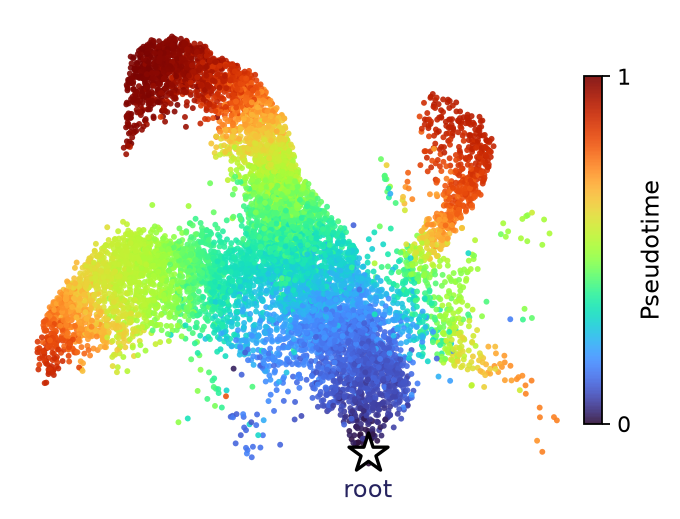

/path/to/ChronoClone/reference_workspace/Figure/weinreb_pseudotime_branch_panels_20260917/panels/figure_2b_pseudotime_landscape.svg


In [2]:

# Panel 1: the pseudotime landscape on its own (no trajectories), with the Palantir root marked.
stem = 'figure_2b_pseudotime_landscape'
fig = plt.figure(figsize=(4.6, 4.2), dpi=160)
ax = fig.add_axes([0.02, 0.03, 0.80, 0.94])
scatter = ax.scatter(U[:, 0], U[:, 1], c=PT, cmap='turbo', s=7, lw=0, alpha=.9, rasterized=True)
ax.scatter([ROOT_XY[0]], [ROOT_XY[1]], marker='*', s=340, c='white', edgecolors='black', lw=1.5, zorder=7)
ax.text(ROOT_XY[0], ROOT_XY[1] - 1.2, 'root', fontsize=11, color='#26235F', ha='center', va='top', zorder=7)
ax.set_xlim(*XLIM); ax.set_ylim(*YLIM); ax.set_aspect('equal'); ax.set_axis_off()
bar = fig.colorbar(scatter, ax=ax, fraction=.035, pad=.01, shrink=.55)
bar.set_label('Pseudotime', fontsize=11); bar.ax.tick_params(labelsize=10)
bar.set_ticks([np.nanmin(PT), np.nanmax(PT)]); bar.set_ticklabels(['0', '1'])
svg = OUT / 'panels' / f'{stem}.svg'; png = svg.with_suffix('.png')
fig.savefig(svg); fig.savefig(png, dpi=300)
display(fig); plt.close(fig)
panel_records.append({'stem': stem, 'content': 'Palantir pseudotime UMAP, root star, no trajectories',
                      'svg_sha256': sha256(svg), 'png_sha256': sha256(png)})
print(svg)


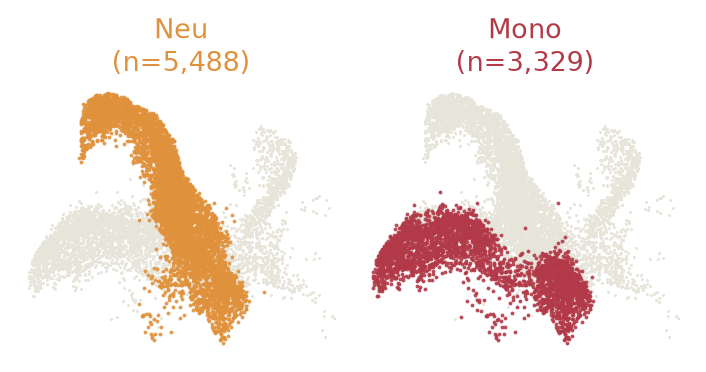

/path/to/ChronoClone/reference_workspace/Figure/weinreb_pseudotime_branch_panels_20260917/panels/figure_2c_branch_cells_neu_mono.svg


In [3]:

# Panel 2 (main): neutrophil- and monocyte-compatible cells, one map each.
stem = 'figure_2c_branch_cells_neu_mono'; branches = ['Neu', 'Mono']
n = len(branches)
fig = plt.figure(figsize=(2.15 * n, 2.45), dpi=160)
for i, branch in enumerate(branches):
    mask = MASKS[branch]
    ax = fig.add_axes([(0.02 + i) / n, 0.02, 0.96 / n, 0.84])
    ax.scatter(U[~mask, 0], U[~mask, 1], s=2.0, c='#E7E4DA', lw=0, rasterized=True)
    ax.scatter(U[mask, 0], U[mask, 1], s=3.0, c=BRANCH_COLORS[branch], lw=0, alpha=.9, rasterized=True)
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM); ax.set_aspect('equal'); ax.set_axis_off()
    ax.set_title(f'{branch}\n(n={mask.sum():,d})', fontsize=12, color=BRANCH_COLORS[branch], pad=2)
svg = OUT / 'panels' / f'{stem}.svg'; png = svg.with_suffix('.png')
fig.savefig(svg); fig.savefig(png, dpi=300)
display(fig); plt.close(fig)
panel_records.append({'stem': stem, 'content': 'branch-compatible cells: ' + ', '.join(branches),
                      'svg_sha256': sha256(svg), 'png_sha256': sha256(png)})
print(svg)


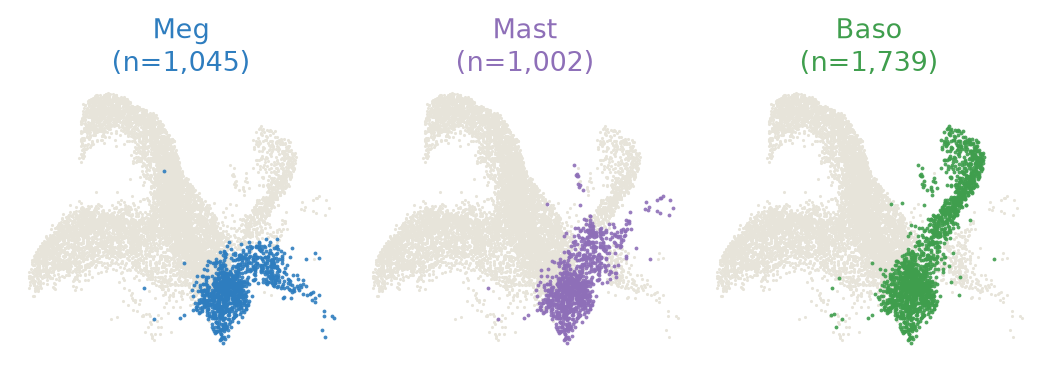

/path/to/ChronoClone/reference_workspace/Figure/weinreb_pseudotime_branch_panels_20260917/panels/figure_s2_branch_cells_meg_mast_baso.svg


In [4]:

# Supplementary panel: the remaining branches, same display.
stem = 'figure_s2_branch_cells_meg_mast_baso'; branches = ['Meg', 'Mast', 'Baso']
n = len(branches)
fig = plt.figure(figsize=(2.15 * n, 2.45), dpi=160)
for i, branch in enumerate(branches):
    mask = MASKS[branch]
    ax = fig.add_axes([(0.02 + i) / n, 0.02, 0.96 / n, 0.84])
    ax.scatter(U[~mask, 0], U[~mask, 1], s=2.0, c='#E7E4DA', lw=0, rasterized=True)
    ax.scatter(U[mask, 0], U[mask, 1], s=3.0, c=BRANCH_COLORS[branch], lw=0, alpha=.9, rasterized=True)
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM); ax.set_aspect('equal'); ax.set_axis_off()
    ax.set_title(f'{branch}\n(n={mask.sum():,d})', fontsize=12, color=BRANCH_COLORS[branch], pad=2)
svg = OUT / 'panels' / f'{stem}.svg'; png = svg.with_suffix('.png')
fig.savefig(svg); fig.savefig(png, dpi=300)
display(fig); plt.close(fig)
panel_records.append({'stem': stem, 'content': 'branch-compatible cells: ' + ', '.join(branches),
                      'svg_sha256': sha256(svg), 'png_sha256': sha256(png)})
print(svg)


In [5]:

records = pd.DataFrame(panel_records)
records.to_csv(OUT / 'tables/panel_manifest.csv', index=False)
display(records)


,stem,content,svg_sha256,png_sha256
0,figure_2b_pseudotime_landscape,"Palantir pseudotime UMAP, root star, no trajec...",8ba0b11b5a3532a0c287d6a95bf1b03538c1b6fb56ad90...,d4dc37fce5cc6ae4f27cb8d518a45883ab1ec4d43c9477...
1,figure_2c_branch_cells_neu_mono,"branch-compatible cells: Neu, Mono",16aad7ef3cb3a87286c72793cf8d77425af1993269cd1c...,324f207e63c280dfb3e6f53df26532aa882fa5e54a2dab...
2,figure_s2_branch_cells_meg_mast_baso,"branch-compatible cells: Meg, Mast, Baso",5dee553e6c142098abf30c633fc34576972aa2270f3787...,fff2950a173f03d16f766c0ca96e60e86bdcc68cf5ee0d...
